# Political group or national party

Roadmap step 3, part 2. Members are elected on national party lists but vote in European political groups. When the two pull in different directions, whose line do members vote with?

**Definitions** (shared code in `explanation.py`):

- The **group line** is the group's most common position among For, Against and Abstention, with the member included (see notebook 01).
- The **national party line** is the position all of the member's other active colleagues from the same national party and the same group took, when there are at least two of them. If they disagree among themselves, there is no national party line. This is revealed from votes, not a recorded instruction, and it exists only when the delegation votes as one.
- A **conflict** is a roll call where both lines exist and differ.

The two lines aren't built the same way: the national line needs a unanimous delegation, the group line only a plurality. So the share voting with the national party has to be read against two references: how often members vote with united colleagues when the lines agree, and a placebo where the colleagues are replaced by random members of the same group.

Contested roll calls as before (2.5%). Non-attached members have no group line and are left out.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from explanation import NON_ATTACHED, POSITIONS, defection_rows, follows, independent_party_ids
from howtheyvote import load, load_rollcalls, load_votes

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1 to 3
NEUTRAL = "#52514e"
MUTED = "#c9c8c1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})

TERMS = [9, 10]
# Display order from the polarization clustering maps; non-attached members last.
GROUP_ORDER = ["GREEN_EFA", "GUE_NGL", "SD", "RENEW", "EPP", "ECR", "ID", "PFE", "ESN", "NI"]
LABELS = {"GUE_NGL": "The Left", "GREEN_EFA": "Greens/EFA", "SD": "S&D", "RENEW": "Renew", "EPP": "EPP",
          "ECR": "ECR", "ID": "ID", "PFE": "PfE", "ESN": "ESN", "NI": "Non-attached"}
TERM_10_START = pd.Timestamp("2024-07-16")


def half_label(value):
    return f"{int(value)} {'H2' if value % 1 else 'H1'}"


def ordered(index):
    return [g for g in GROUP_ORDER if g in set(index)]


rollcalls = load_rollcalls()
rollcalls = rollcalls[~rollcalls["is_secret"]].set_index("vote_id")
rollcalls["half"] = rollcalls["date"].dt.year + (rollcalls["date"].dt.month > 6) * 0.5
# Responsible committee as the topic of a roll call. 1,196 roll calls have two or three (joint committees).
committees = load("subjects").query("scheme == 'committee'")
joint = committees.groupby("vote_id")["code"].nunique() > 1
first = committees.drop_duplicates("vote_id").set_index("vote_id")
rollcalls["committee"] = first["code"].where(~joint.reindex(first.index), "JOINT")
COMMITTEE_LABELS = dict(zip(committees["code"], committees["label"])) | {"JOINT": "Joint committees"}

# Members filed under the export's "Independent" entries have no national party.
independents = independent_party_ids(load("national_parties"))
frames = []
for term in TERMS:
    votes = load_votes(term)
    # Seats: members of the national party in the same group listed on the roll call, whatever their position.
    seats = votes.groupby(["vote_id", "group_code", "national_party_id"], observed=True).size().rename("party_seats").reset_index()
    seats["group_code"] = seats["group_code"].astype(str)
    term_rows = defection_rows(votes, no_party_ids=independents)
    frames.append(term_rows.merge(seats, on=["vote_id", "group_code", "national_party_id"], how="left"))
    del votes, term_rows
rows = pd.concat(frames, ignore_index=True)
del frames
rows = rows.join(rollcalls[["half", "minority_share", "minority_share_with_abstention", "vote_part",
                            "committee"]], on="vote_id")
contested = rows[rows["minority_share"] >= 0.025]
print(f"{len(rows):,} active positions; {len(contested):,} on contested roll calls")

from explanation import placebo_colleagues

grouped = contested[contested["group_code"] != NON_ATTACHED].copy()
both = grouped.dropna(subset=["conflict"])
print("What members' national colleagues did, share of group members' positions:")
display(grouped.groupby("term")["colleagues"].value_counts(normalize=True).unstack().round(3))
print("Share of positions against united national colleagues, when the two lines agree:",
      both[both["conflict"] == 0].groupby("term")["defected_party"].mean().round(4).to_dict())

16,616,129 active positions; 15,624,395 on contested roll calls


What members' national colleagues did, share of group members' positions:


colleagues,colleagues divided,too few colleagues,united against the group,united with the group
term,,,,
9,0.056,0.293,0.044,0.606
10,0.061,0.286,0.038,0.615


Share of positions against united national colleagues, when the two lines agree: {np.int8(9): 0.0067, np.int8(10): 0.007}


## How often the two lines conflict, and whom members vote with

In [2]:
conflicts = both[both["conflict"] == 1].copy()
conflicts["follows"] = follows(conflicts)
table = both.groupby(["term", "group_code"]).agg(positions=("conflict", "size"), conflict_rate=("conflict", "mean"))
table = table.join(conflicts.groupby(["term", "group_code"])["follows"].value_counts(normalize=True).unstack(fill_value=0))
table["share_of_conflict_positions"] = conflicts.groupby(["term", "group_code"]).size() / conflicts.groupby("term").size()
overall = both.groupby("term").agg(positions=("conflict", "size"), conflict_rate=("conflict", "mean")).join(
    conflicts.groupby("term")["follows"].value_counts(normalize=True).unstack(fill_value=0))
table = pd.concat([table, overall.assign(group_code="all groups").set_index("group_code", append=True)])
table = table.reindex(pd.MultiIndex.from_product([TERMS, GROUP_ORDER[:-1] + ["all groups"]])).dropna(how="all")
display(table.rename(index=LABELS, level=1).round(3))

# The pooled share counts each member of a large delegation separately. Two other ways of weighting it:
events = conflicts.groupby(["term", "vote_id", "group_code", "national_party_id"])["follows"].apply(
    lambda s: s.eq("national party").mean()).groupby("term").mean()
per_group = table.drop(index="all groups", level=1)["national party"].groupby(level=0).mean()
print("Share voting with the national party, weighted three ways:")
display(pd.DataFrame({"pooled positions": overall["national party"], "national party per roll call": events,
                      "mean of groups": per_group}).round(3))

positions  conflict_rate  group  national party  neither  \
9  Greens/EFA   741105.0          0.008  0.047           0.941    0.012   
   The Left     238152.0          0.052  0.051           0.932    0.017   
   S&D         1686425.0          0.027  0.045           0.945    0.010   
   Renew        865636.0          0.070  0.030           0.962    0.009   
   EPP         2010048.0          0.036  0.059           0.926    0.015   
   ECR          736414.0          0.129  0.016           0.976    0.007   
   ID           949502.0          0.211  0.004           0.993    0.003   
   all groups  7227282.0          0.068  0.023           0.970    0.007   
10 Greens/EFA   154606.0          0.018  0.065           0.923    0.012   
   The Left     122781.0          0.065  0.023           0.960    0.017   
   S&D          542778.0          0.024  0.056           0.930    0.014   
   Renew        184871.0          0.057  0.036           0.958    0.006   
   EPP          679896.0          0.035  0.056           0.920    0.024   
   ECR          286757.0          0.089  0.028           0.964    0.008   
   PfE          386558.0          0.146  0.007           0.989    0.004   
   ESN           85780.0          0.021  0.095           0.882    0.023   
   all groups  2444027.0          0.058  0.029           0.961    0.010   

               share_of_conflict_positions  
9  Greens/EFA                        0.012  
   The Left                          0.025  
   S&D                               0.092  
   Renew                             0.123  
   EPP                               0.146  
   ECR                               0.193  
   ID                                0.407  
   all groups                          NaN  
10 Greens/EFA                        0.019  
   The Left                          0.056  
   S&D                               0.093  
   Renew                             0.074  
   EPP                               0.168  
   ECR                               0.180  
   PfE                               0.398  
   ESN                               0.012  
   all groups                          NaN

Share voting with the national party, weighted three ways:


,pooled positions,national party per roll call,mean of groups
9,0.970,0.847,0.954
10,0.961,0.823,0.941


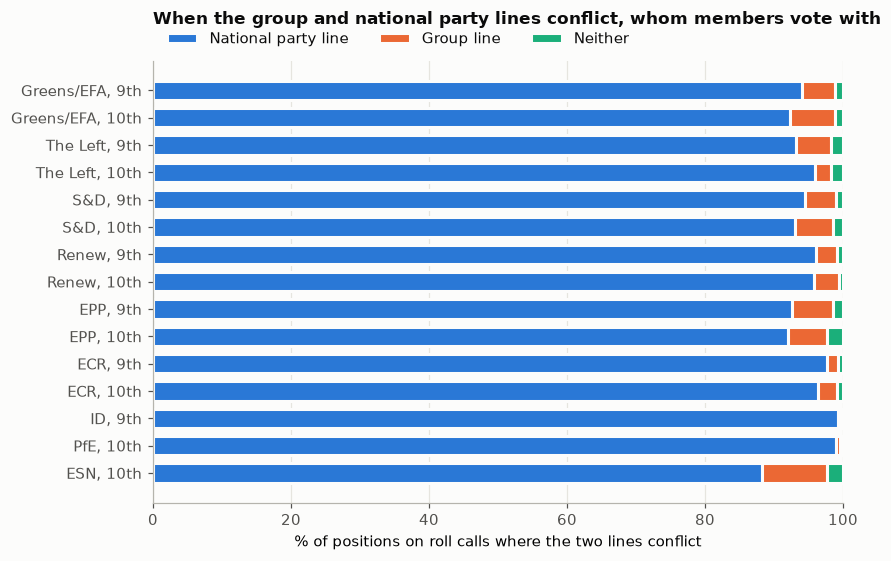

In [3]:
shares = conflicts.groupby(["group_code", "term"])["follows"].value_counts(normalize=True).unstack(fill_value=0)
shares = shares.reindex(pd.MultiIndex.from_tuples([(g, t) for g in ordered(conflicts["group_code"]) for t in TERMS
                                                    if (g, t) in shares.index]))
labels = [f"{LABELS[g]}, {t}th" for g, t in shares.index]
fig, axis = plt.subplots(figsize=(8, 5.2))
positions = np.arange(len(shares))[::-1]
left = np.zeros(len(shares))
for column, color, name in zip(["national party", "group", "neither"], SERIES,
                               ["National party line", "Group line", "Neither"]):
    axis.barh(positions, shares[column] * 100, left=left, color=color, label=name, height=0.7,
              edgecolor="#fcfcfb", linewidth=2)
    left += shares[column].to_numpy() * 100
axis.set_yticks(positions, labels)
axis.set_xlim(0, 100)
axis.set_xlabel("% of positions on roll calls where the two lines conflict")
axis.set_title("When the group and national party lines conflict, whom members vote with", pad=24)
axis.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
axis.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**What this shows**

- **What colleagues did.** On about 61% of group members' positions, their national colleagues in the group were united behind the group line, and on about 4% united against it. They were divided on 6%. On 29% the member had too few colleagues for a line.
- **Where both lines exist, they conflict on 6.8% of positions in the 9th term and 5.8% in the 10th.** Conflicts are rare in Greens/EFA (0.8% and 1.8%), S&D (2.7% and 2.4%) and ESN (2.1%). They are common in ID (21.1%), PfE (14.6%) and ECR (12.9% and 8.9%).
- **When the lines conflict, members vote with their united national colleagues on 97.0% and 96.1% of positions,** and with the group line on 2.3% and 2.9%. When the lines agree, members vote against united colleagues on only 0.67% and 0.70%. So a conflict barely moves them away from their colleagues, while agreement with the group line collapses.
- **Weighting matters.** ID and PfE make up about 40% of conflict positions, and they vote with the national party 99%. Other ways of counting:
  - The mean over groups is 95.4% and 94.1%; the lowest are the EPP (92.6% and 92.0%) and ESN (88.2%).
  - Counting each national party on each roll call once gives 84.7% and 82.3%. This measure is lower by construction: when one member of a delegation votes differently from the rest, only that member has a united-colleagues line, so the roll call counts as one member not voting with the national party.

## Is this only how the lines are defined?

Three checks:

1. **Placebo colleagues.** For a sample of 300,000 positions, each member's colleagues are replaced by the same number of random members of the same group from other national parties. The placebo line needs the same unanimity. If voting with the national party only reflected the definition, members would vote with placebo colleagues on placebo conflicts about as often as with real ones.
2. **Group line without the member's own party.** A large delegation makes up much of its group's line. Here the group line is taken from the other national parties in the group only.
3. **Clear group lines only.** Conflicts where at least 60% of the group's other national parties' members took the group line.

In [4]:
rng = np.random.default_rng(0)
candidates = grouped[(grouped["party_others"] >= 2) & (grouped["group_line"] >= 0)]
sample = candidates.sample(300000, random_state=0)
placebo = placebo_colleagues(sample, rng)
sample = sample.join(placebo)
placebo_conflicts = sample[sample["placebo_conflict"] == 1]
real_conflicts = sample[sample["conflict"] == 1]
print(f"Sample: {len(sample):,} positions. Conflict rate: real colleagues {sample['conflict'].mean():.3f}, "
      f"placebo colleagues {sample['placebo_conflict'].mean():.3f}")
display(pd.DataFrame({
    "real colleagues": [len(real_conflicts), (real_conflicts["position_code"] == real_conflicts["party_line"]).mean(),
                        (real_conflicts["position_code"] == real_conflicts["group_line"]).mean()],
    "placebo colleagues": [len(placebo_conflicts),
                           (placebo_conflicts["position_code"] == placebo_conflicts["placebo_line"]).mean(),
                           (placebo_conflicts["position_code"] == placebo_conflicts["group_line"]).mean()],
}, index=["conflict positions", "votes with the colleagues", "votes with the group"]).round(3))

Sample: 300,000 positions. Conflict rate: real colleagues 0.065, placebo colleagues 0.004


,real colleagues,placebo colleagues
conflict positions,17970.000,765.000
votes with the colleagues,0.967,0.230
votes with the group,0.023,0.629


In [5]:
outside = grouped.dropna(subset=["conflict_outside"])
outside_conflicts = outside[outside["conflict_outside"] == 1].copy()
outside_conflicts["follows"] = follows(outside_conflicts, "group_line_outside")
counts = outside_conflicts[["outside_for", "outside_against", "outside_abstention"]].to_numpy()
share = counts[np.arange(len(counts)), outside_conflicts["group_line_outside"].to_numpy()] / counts.sum(axis=1)
clear = outside_conflicts[share >= 0.6]
display(pd.concat({
    "group line": conflicts.groupby("term")["follows"].value_counts(normalize=True).unstack(),
    "group line without own party": outside_conflicts.groupby("term")["follows"].value_counts(normalize=True).unstack(),
    "same, at least 60% of the rest behind it": clear.groupby("term")["follows"].value_counts(normalize=True).unstack(),
}).round(3))
print("Conflict rate against the line without the member's own party:",
      outside.groupby("term")["conflict_outside"].mean().round(3).to_dict())

follows                                        group  national party  neither
                                         term                                
group line                               9     0.023           0.970    0.007
                                         10    0.029           0.961    0.010
group line without own party             9     0.018           0.976    0.006
                                         10    0.024           0.967    0.009
same, at least 60% of the rest behind it 9     0.021           0.973    0.006
                                         10    0.028           0.963    0.009

Conflict rate against the line without the member's own party: {np.int8(9): 0.093, np.int8(10): 0.074}


**What this shows**

- **The definition doesn't produce the result.** With placebo colleagues drawn at random from other parties in the same group, conflicts are rare (0.4% of positions against 6.5%). On those conflicts members vote with the placebo colleagues only 23% of the time and with the group 63%. With their real colleagues it is 96.7%.
- **Large delegations shaping the group line don't produce it either.** Against the group line without the member's own national party, conflicts are more common (9.3% and 7.4%), and members vote with their national party on 97.6% and 96.7% of them.
- **Clear group lines don't change it:** 97.3% and 96.3% where at least 60% of the other parties' members took the group line.

Members of the same national party may vote together because they share views, receive instructions, or both. These checks show the pattern isn't an artefact of the measures, not which of those it is.

## What colleagues did when members defected

Each defection from the group line by what the member's national colleagues in the group did: united against the group line (and the member voted with them), united but the member voted differently from them, divided, or too few colleagues (none or one active, or no national party).

In [6]:
defections = grouped[grouped["defected_group"] == 1].copy()
defections["case"] = np.where(
    (defections["colleagues"] == "united against the group") & (defections["position_code"] == defections["party_line"]),
    "with united colleagues",
    np.where(defections["colleagues"].isin(["united against the group", "united with the group"]),
             "against united colleagues", defections["colleagues"]))
cases = defections.groupby(["term", "group_code"])["case"].value_counts(normalize=True).unstack(fill_value=0)
overall = defections.groupby("term")["case"].value_counts(normalize=True).unstack(fill_value=0)
cases = pd.concat([cases, overall.assign(group_code="all groups").set_index("group_code", append=True)])
cases = cases.reindex(pd.MultiIndex.from_product([TERMS, GROUP_ORDER[:-1] + ["all groups"]])).dropna(how="all")
display(cases.rename(index=LABELS, level=1).round(3))
united = defections[defections["colleagues"].isin(["united against the group", "united with the group"])]
print("Among defections where colleagues were united, share with them:",
      united.groupby("term")["case"].apply(lambda s: s.eq("with united colleagues").mean()).round(3).to_dict())

case           against united colleagues  colleagues divided  \
9  Greens/EFA                      0.107               0.231   
   The Left                        0.035               0.083   
   S&D                             0.091               0.289   
   Renew                           0.048               0.107   
   EPP                             0.082               0.288   
   ECR                             0.027               0.080   
   ID                              0.015               0.088   
   all groups                      0.050               0.163   
10 Greens/EFA                      0.061               0.119   
   The Left                        0.039               0.086   
   S&D                             0.106               0.340   
   Renew                           0.038               0.064   
   EPP                             0.094               0.324   
   ECR                             0.035               0.184   
   PfE                             0.017               0.084   
   ESN                             0.083               0.137   
   all groups                      0.057               0.192   

case           too few colleagues  with united colleagues  
9  Greens/EFA               0.450                   0.211  
   The Left                 0.695                   0.187  
   S&D                      0.274                   0.346  
   Renew                    0.407                   0.437  
   EPP                      0.325                   0.305  
   ECR                      0.272                   0.622  
   ID                       0.148                   0.749  
   all groups               0.301                   0.487  
10 Greens/EFA               0.620                   0.200  
   The Left                 0.488                   0.387  
   S&D                      0.202                   0.352  
   Renew                    0.486                   0.412  
   EPP                      0.294                   0.288  
   ECR                      0.340                   0.441  
   PfE                      0.118                   0.781  
   ESN                      0.671                   0.109  
   all groups               0.309                   0.441

Among defections where colleagues were united, share with them: {np.int8(9): 0.907, np.int8(10): 0.885}


**What this shows**

- **About half of group defections are with united national colleagues:** 48.7% in the 9th term and 44.1% in the 10th.
  - 5.0% and 5.7% go against united colleagues too.
  - 16.3% and 19.2% come from members whose colleagues were divided.
  - 30.1% and 30.9% from members with too few colleagues for a line.
- **Where colleagues were united, 90.7% and 88.5% of defections are with them.**
- **In some groups on the right, defection is mostly national parties breaking away together:** ID (74.9%), PfE (78.1%) and ECR in the 9th term (62.2%). This is less so for ECR in the 10th term (44.1%), and not for ESN (10.9%), where most defectors have too few colleagues for a line (67.1%).
- **In Greens/EFA and The Left, many defections are by members with too few colleagues** (45% to 70%), so they are more individual or by very small delegations.

## Delegation size

Number of the member's other active colleagues from the same national party in the group.

In [7]:
both["size"] = pd.cut(both["party_others"], [1, 2, 4, 9, 200], labels=["2", "3 to 4", "5 to 9", "10 or more"])
conflicts = conflicts.join(both["size"])
size_table = both.groupby(["term", "size"], observed=True).agg(
    positions=("conflict", "size"), conflict_rate=("conflict", "mean"),
    conflict_rate_without_own_party=("conflict_outside", "mean"))
size_table = size_table.join(conflicts.groupby(["term", "size"], observed=True)["follows"].value_counts(
    normalize=True).unstack(fill_value=0))
display(size_table.round(3))

positions  conflict_rate  conflict_rate_without_own_party  \
term size                                                                    
9    2              899727          0.129                            0.131   
     3 to 4        1638792          0.074                            0.076   
     5 to 9        1711419          0.048                            0.054   
     10 or more    2977344          0.058                            0.111   
10   2              377997          0.085                            0.087   
     3 to 4         479819          0.072                            0.075   
     5 to 9         569952          0.084                            0.094   
     10 or more    1016259          0.026                            0.055   

                 group  national party  neither  
term size                                        
9    2           0.029           0.961    0.010  
     3 to 4      0.033           0.956    0.011  
     5 to 9      0.035           0.957    0.008  
     10 or more  0.007           0.991    0.003  
10   2           0.054           0.930    0.016  
     3 to 4      0.037           0.948    0.015  
     5 to 9      0.013           0.981    0.006  
     10 or more  0.015           0.979    0.006

**What this shows**

- **Smaller delegations conflict with their group more often:** 12.9% of positions for members with two colleagues in the 9th term, against 5.8% for delegations of ten or more.
- **But large delegations conflict less partly because they shape the line.** Against the line without their own party, delegations of ten or more conflict on 11.1% and 5.5%, about twice as often.
- **Members vote with their national party on 93% or more of conflicts whatever the size,** and on 98% to 99% in the largest delegations.

## By kind of roll call

In [8]:
part_table = both.groupby(["term", "vote_part"]).agg(positions=("conflict", "size"), conflict_rate=("conflict", "mean"))
part_table = part_table.join(conflicts.groupby(["term", "vote_part"])["follows"].value_counts(normalize=True).unstack(fill_value=0))
display(part_table.round(3))

positions  conflict_rate  group  national party  neither
term vote_part                                                           
9    amendment     4260813          0.064  0.024           0.969    0.006
     final          567228          0.076  0.023           0.970    0.008
     other          179880          0.056  0.015           0.979    0.005
     procedural      53626          0.043  0.048           0.938    0.014
     text part     2165735          0.076  0.021           0.970    0.009
10   amendment     1587525          0.053  0.030           0.961    0.009
     final          242234          0.073  0.021           0.970    0.009
     other           35728          0.061  0.029           0.961    0.011
     procedural      28564          0.036  0.036           0.953    0.011
     text part      549976          0.068  0.029           0.957    0.014

**Conflicts are a little more common on final votes and parts of a text** (6.8% to 7.6%) than on amendments (5.3% and 6.4%). The share voting with the national party is above 93% on every kind of roll call.

## Which national parties conflict most with their group

National parties with at least 200 positions with both lines in the term, ranked by conflict rate, with the rate against the group line without the party itself. Names are the export's labels.

In [9]:
parties = load("national_parties").set_index("national_party_id")
by_party = both.groupby(["term", "national_party_id"]).agg(
    positions=("conflict", "size"), conflict_rate=("conflict", "mean"),
    conflict_without_own_party=("conflict_outside", "mean"),
    group=("group_code", lambda s: s.mode()[0]), country=("country_code", "first"), members=("member_id", "nunique"))
by_party = by_party[by_party["positions"] >= 200]
by_party["party"] = parties["label"].reindex(by_party.index.get_level_values(1)).to_numpy()
by_party["group"] = by_party["group"].map(LABELS)
for term in TERMS:
    data = by_party.loc[term].sort_values("conflict_rate", ascending=False)
    print(f"{term}th term: {len(data)} national parties; conflict rate median {data['conflict_rate'].median():.3f}")
    display(data.head(12)[["party", "country", "group", "members", "positions", "conflict_rate",
                           "conflict_without_own_party"]].round(3))

9th term: 80 national parties; conflict rate median 0.036


,party,country,group,members,positions,conflict_rate,conflict_without_own_party
national_party_id,,,,,,,
5533,Forum voor Democratie,NLD,ECR,3,14876,0.451,0.462
6260,JA21,NLD,ECR,4,24883,0.442,0.446
5233,Conservative Party,GBR,ECR,4,1476,0.388,0.388
5393,Sverigedemokraterna,SWE,ECR,4,45279,0.380,0.386
5173,Nieuw-Vlaamse Alliantie,BEL,ECR,3,44641,0.358,0.364
5164,Freiheitliche Partei Österreichs,AUT,ID,3,49892,0.313,0.328
5170,Vlaams Belang,BEL,ID,3,46011,0.301,0.317
5369,Alternative für Deutschland,DEU,ID,11,155765,0.267,0.335
5494,Rassemblement national,FRA,ID,26,324022,0.203,0.382


10th term: 76 national parties; conflict rate median 0.044


,party,country,group,members,positions,conflict_rate,conflict_without_own_party
national_party_id,,,,,,,
6754,Nieuw-Vlaamse Alliantie,BEL,ECR,3,7756,0.316,0.323
6810,Sverigedemokraterna,SWE,ECR,3,17602,0.257,0.261
6794,ANO 2011,CZE,PfE,8,35374,0.237,0.256
6747,Freiheitliche Partei Österreichs,AUT,PfE,6,34506,0.228,0.248
6807,Freie Wähler,DEU,Renew,3,12764,0.217,0.219
7876,Identité Libertés,FRA,ECR,4,20339,0.211,0.216
6856,Konfederacja Wolność i Niepodległość,POL,ESN,5,9556,0.205,0.210
6737,Fidesz-Magyar Polgári Szövetség-Kereszténydemo...,HUN,PfE,12,45341,0.203,0.230
6696,Partij voor de Vrijheid,NLD,PfE,7,32828,0.198,0.218


**What this shows**

- **The national parties that conflict most with their group are mostly in ECR, ID and PfE.**
  - 9th term, ECR: Forum voor Democratie and JA21 (Netherlands), the UK Conservatives before Brexit, Sverigedemokraterna (Sweden) and N-VA (Belgium).
  - 9th term, ID: FPÖ (Austria), Vlaams Belang (Belgium), AfD (Germany) and Rassemblement National (France).
  - 10th term: PfE parties such as ANO 2011, FPÖ, Fidesz and PVV conflict on about 20% to 24% of positions.
- **Outside the right,** Les Républicains (EPP, 18%) and Freie Wähler (Renew, 22%) stand out.
- **The line without the party itself matters for the largest delegations.** Rassemblement National conflicts on 20% of positions with the full group line but 38% with the line of ID's other parties.
- The median national party conflicts with its group on 3.6% and 4.4% of positions.

These describe recorded votes; why each party diverges isn't studied here.

## Sensitivity

In [10]:
def follow_share(frame):
    frame = frame[(frame["group_code"] != NON_ATTACHED) & (frame["conflict"] == 1)]
    return frame.assign(follows=follows(frame)).groupby("term")["follows"].value_counts(normalize=True).unstack()


display(pd.concat({
    "all roll calls": follow_share(rows),
    "contested (2.5%)": follow_share(contested),
    "contested (10%)": follow_share(rows[rows["minority_share"] >= 0.10]),
    "contested, abstention against (2.5%)": follow_share(rows[rows["minority_share_with_abstention"] >= 0.025]),
    "at least 3 colleagues": follow_share(contested[contested["party_others"] >= 3]),
}).round(3))

follows                                    group  national party  neither
                                     term                                
all roll calls                       9     0.023           0.970    0.007
                                     10    0.028           0.961    0.010
contested (2.5%)                     9     0.023           0.970    0.007
                                     10    0.029           0.961    0.010
contested (10%)                      9     0.025           0.967    0.008
                                     10    0.029           0.960    0.011
contested, abstention against (2.5%) 9     0.023           0.970    0.007
                                     10    0.028           0.961    0.010
at least 3 colleagues                9     0.021           0.972    0.007
                                     10    0.021           0.970    0.009

**Members vote with their national party on 96.0% to 97.2% of conflicts under every rule,** including when the national party line needs at least three united colleagues.

## Summary

- **On conflicts, members vote with the national party.** When a member's united national colleagues in the group take a different line from the group, members vote with the colleagues on about 96% to 97% of positions in both terms, and with the group on about 2% to 3%. When the lines agree, they vote against united colleagues on under 1%.
- **The checks:**
  - With random placebo colleagues the share is 23%.
  - Against the group line without the member's own party, and on clear group lines only, it stays at 96% to 98%.
  - Counted once per national party and roll call it is 82% to 85%, lower by construction.
- **ID and PfE dominate the pooled figure.** Groups range from 88% (ESN) to 99%.
- **Defection is about half collective.** About half of group defections are with united national colleagues, and 89% to 91% where colleagues were united. This is most marked in ID, PfE and 9th-term ECR.
- **What it describes.** The national line is revealed from votes, so this describes behaviour. It doesn't show whether national parties instruct their members or share views.